In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

In [2]:
import os
# from collections import Counter
# from PIL import Image

root = "/kaggle/input/datasets//grassknoted/asl-alphabet/asl_alphabet_train/asl_alphabet_train"
# sizes, modes, bad = Counter(), Counter(), []

# for cls in sorted(os.listdir(root)):
#     folder = os.path.join(root, cls)
#     count = 0
#     for f in os.listdir(folder):
#         path = os.path.join(folder, f)
#         try:
#             with Image.open(path) as im:
#                 sizes[im.size] += 1
#                 modes[im.mode] += 1
#             count += 1
#         except Exception:
#             bad.append(path)
#     print(f"{cls:8s} {count}")

# print("Sizes:", sizes)
# print("Modes:", modes)
# print("Corrupt files:", bad)

In [3]:
import os, re
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

ROOT = "/kaggle/input/datasets/grassknoted/asl-alphabet/asl_alphabet_train/asl_alphabet_train"
IMG = 64
BATCH = 64
AUTOTUNE = tf.data.AUTOTUNE # <- using the GPU

class_names = sorted(os.listdir(ROOT))   # 29 classes
class_to_idx = {c: i for i, c in enumerate(class_names)}

In [4]:
import random
def num(fname):
    return int(re.findall(r"\d+", fname)[-1])

train_p, train_y, val_p, val_y, test_p, test_y = [], [], [], [], [], []

for c in class_names:
    files = os.listdir(os.path.join(ROOT, c))
    random.shuffle(files)
    paths = [os.path.join(ROOT, c, f) for f in files]
    n = len(paths)
    a, b = int(0.70 * n), int(0.85 * n)
    for split_p, split_y, chunk in [(train_p, train_y, paths[:a]),
                                    (val_p,   val_y,   paths[a:b]),
                                    (test_p,  test_y,  paths[b:])]:
        split_p += chunk
        split_y += [class_to_idx[c]] * len(chunk)

print(len(train_p), len(val_p), len(test_p))   # 60900 / 13050 / 13050

60900 13050 13050


In [7]:
def load(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG, IMG))
    img = tf.cast(img, tf.uint8)          # uint8 keeps the cache small (~750 MB for train)
    return img, label

def make_ds(paths, labels, train=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load, num_parallel_calls=AUTOTUNE).cache()
    if train:
        ds = ds.shuffle(10_000, seed=42)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(train_p, train_y, train=True)
val_ds   = make_ds(val_p,   val_y)
test_ds  = make_ds(test_p,  test_y)

In [8]:
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return layers.MaxPooling2D()(x)

inputs = keras.Input(shape=(IMG, IMG, 3))

x = layers.RandomRotation(0.05)(inputs)
x = layers.RandomZoom(0.1)(x)
x = layers.RandomTranslation(0.1, 0.1)(x)
x = layers.RandomBrightness(0.2)(x)
x = layers.RandomContrast(0.2)(x)
x = layers.Rescaling(1./255)(x)

x = conv_block(x, 32)     # 64 -> 32
x = conv_block(x, 64)     # 32 -> 16
x = conv_block(x, 128)    # 16 -> 8

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)

model = keras.Model(inputs, outputs)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 64, 64, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_1            │ (None, 64, 64, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness_1             │ (None, 64, 64, 3)      │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast_1               │ (None, 64, 64, 3)      │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 64, 64, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_8 (ReLU)                  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_9 (ReLU)                  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 64)     │             

 Total params: 292,093 (1.11 MB)

 Trainable params: 291,197 (1.11 MB)

 Non-trainable params: 896 (3.50 KB)

In [9]:
model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks = [
    keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=2),
    keras.callbacks.ModelCheckpoint("asl_cnn.keras", save_best_only=True),
]

history = model.fit(train_ds, validation_data=val_ds,
                    epochs=30, callbacks=callbacks)

Epoch 1/30
952/952 ━━━━━━━━━━━━━━━━━━━━ 1423s 1s/step - accuracy: 0.7254 - loss: 1.0223 - val_accuracy: 0.7074 - val_loss: 0.9373 - learning_rate: 0.0010
Epoch 2/30
952/952 ━━━━━━━━━━━━━━━━━━━━ 47s 49ms/step - accuracy: 0.9126 - loss: 0.3346 - val_accuracy: 0.8946 - val_loss: 0.3242 - learning_rate: 0.0010
Epoch 3/30
952/952 ━━━━━━━━━━━━━━━━━━━━ 47s 49ms/step - accuracy: 0.9510 - loss: 0.1827 - val_accuracy: 0.8880 - val_loss: 0.2983 - learning_rate: 0.0010
Epoch 4/30
952/952 ━━━━━━━━━━━━━━━━━━━━ 47s 49ms/step - accuracy: 0.9672 - loss: 0.1218 - val_accuracy: 0.9701 - val_loss: 0.0909 - learning_rate: 0.0010
Epoch 5/30
952/952 ━━━━━━━━━━━━━━━━━━━━ 46s 49ms/step - accuracy: 0.9754 - loss: 0.0899 - val_accuracy: 0.9709 - val_loss: 0.0933 - learning_rate: 0.0010
Epoch 6/30
952/952 ━━━━━━━━━━━━━━━━━━━━ 46s 49ms/step - accuracy: 0.9802 - loss: 0.0708 - val_accuracy: 0.9469 - val_loss: 0.1698 - learning_rate: 0.0010
Epoch 7/30
952/952 ━━━━━━━━━━━━━━━━━━━━ 47s 49ms/step - accuracy: 0.9884 - l

In [10]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test accuracy: {test_acc:.3f}")

from sklearn.metrics import classification_report, confusion_matrix
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)
print(classification_report(y_true, y_pred, target_names=class_names))

204/204 ━━━━━━━━━━━━━━━━━━━━ 279s 1s/step - accuracy: 0.9999 - loss: 4.5203e-04
Test accuracy: 1.000
204/204 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step
              precision    recall  f1-score   support

           A       1.00      1.00      1.00       450
           B       1.00      1.00      1.00       450
           C       1.00      1.00      1.00       450
           D       1.00      1.00      1.00       450
           E       1.00      1.00      1.00       450
           F       1.00      1.00      1.00       450
           G       1.00      1.00      1.00       450
           H       1.00      1.00      1.00       450
           I       1.00      1.00      1.00       450
           J       1.00      1.00      1.00       450
           K       1.00      1.00      1.00       450
           L       1.00      1.00      1.00       450
           M       1.00      1.00      1.00       450
           N       1.00      1.00      1.00       450
           O       1.00      1.00      1.00   

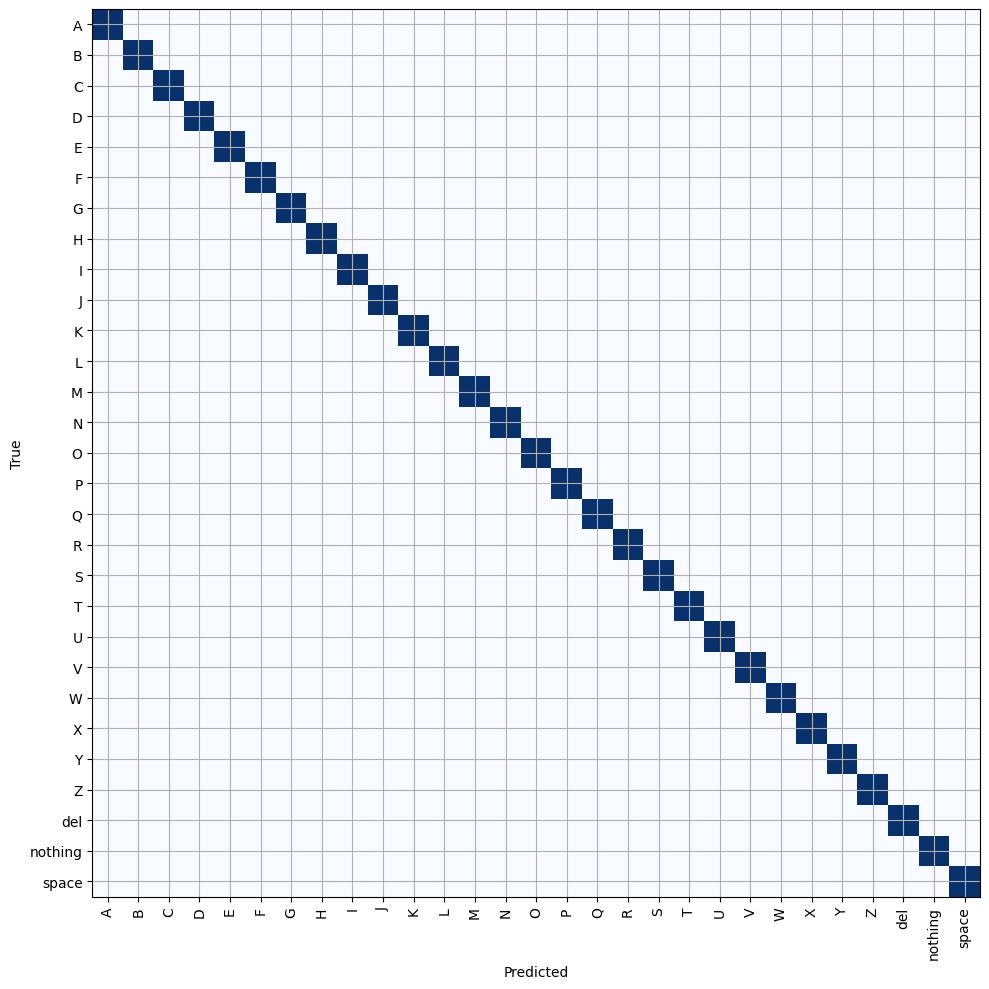

In [11]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(29)); ax.set_xticklabels(class_names, rotation=90)
ax.set_yticks(range(29)); ax.set_yticklabels(class_names)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.grid()
plt.tight_layout(); plt.show()